## **Seaborn Practice**
Seaborn is a Python library built on Matplotlib for creating statistical visualizations easily.

This notebook practices different Seaborn plots using the penguins dataset :)

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [28]:
# List available example dataset names
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [29]:
penguins = sns.load_dataset('penguins')
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### **Scatter Plot & Styling**
This scatter plot shows how flipper length relates to body mass. Colors separate species, and marker shapes separate sex.


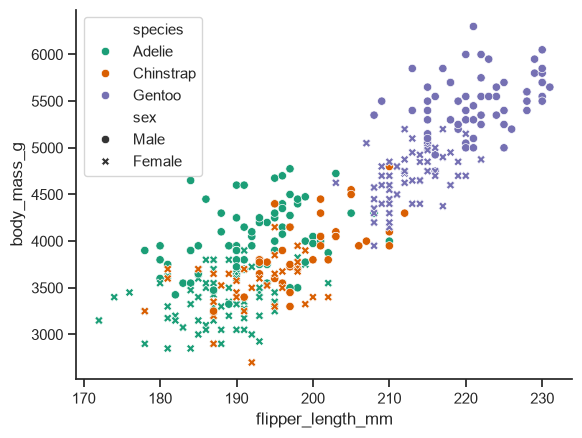

In [30]:
# Scatter plot: relationship between flipper length and body mass
# Color by species and use different markers for sex to make patterns easier to read
# Set the plot style
sns.set_style('ticks')
# Set plot element sizes for notebook display
sns.set_context('notebook')

# Color points by species and change marker shapes by sex
sns.scatterplot(data=penguins,
                x='flipper_length_mm',
                y='body_mass_g',
                hue='species',
                style='sex',
                palette='Dark2') 

# Remove the top and right plot borders
sns.despine()

plt.show()

### **Strip Plot**
This plot shows each value for each species, making it easy to compare the distribution and overlap between groups.


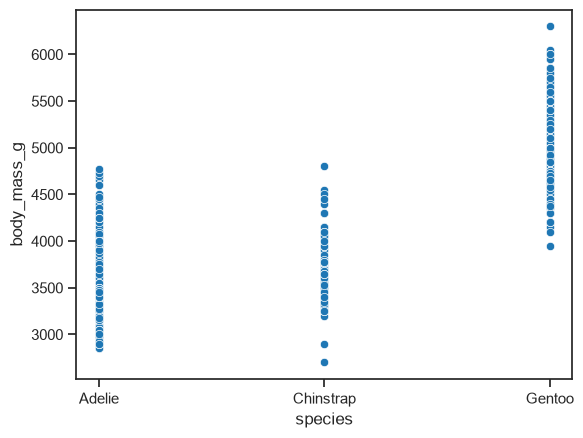

In [31]:
# Simple scatter plot to compare body mass across species
sns.scatterplot(data=penguins, x='species', y='body_mass_g')
plt.show()

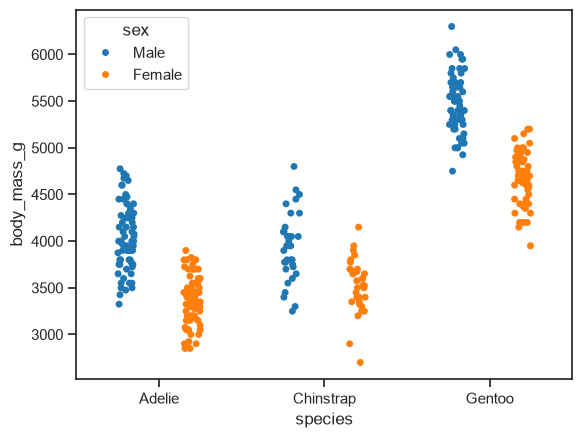

In [32]:
# Strip plot: each point stays visible and groups are separated by sex
# hue: colors the points based on the variable that is passed to it
# dodge: separates the points based on the hue variable 
# jitter: adds random noise to the position of the points to reduce overlap
sns.stripplot(data=penguins, x='species', y='body_mass_g', jitter=True, hue='sex', dodge=True)
plt.show()

### **Swarm Plot**
This plot spreads points so each penguin is visible without overlap, making group differences easier to read.


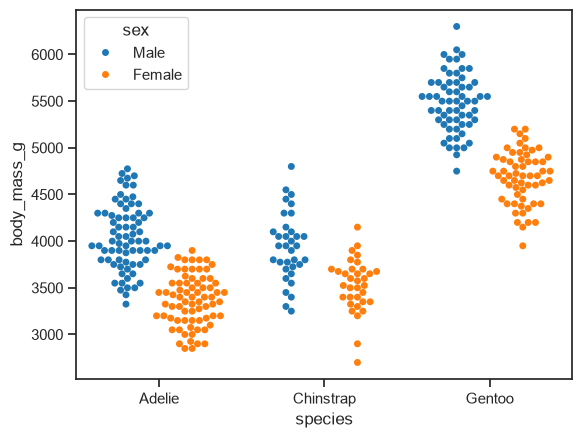

In [33]:
# Swarm plot: avoid overlap so each penguin's value is easy to see
sns.swarmplot(data=penguins, x='species', y='body_mass_g', hue='sex', dodge=True)
plt.show()

### **Histograms**
This histogram shows how body mass is distributed, and the stacked colors help compare the sex groups.


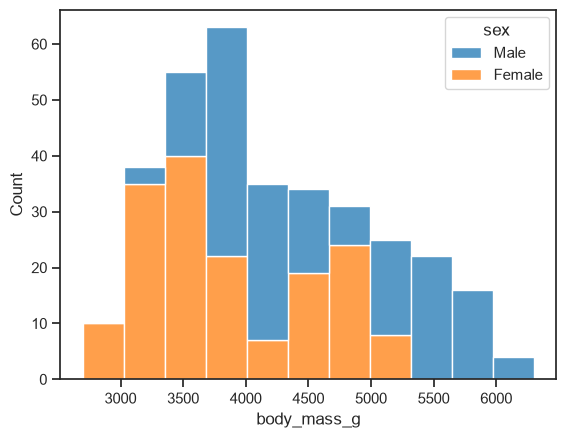

In [34]:
# Histogram: show how body mass is distributed; stack by sex for comparison
# multiple: 'stack' stacks the bars on top of each other
sns.histplot(data=penguins, x='body_mass_g', hue='sex', multiple='stack')
plt.show()

### **Regression Plot**
This adds a trend line to show the overall relationship between body mass and flipper length.


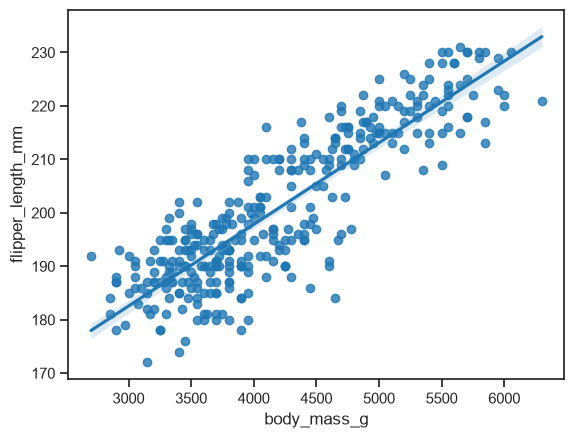

In [35]:
# Regression plot: add a trend line to summarize the relationship
sns.regplot(data=penguins, x='body_mass_g', y='flipper_length_mm')
plt.show()

### **Line Plot**
This line plot compares trends across islands and sex groups.


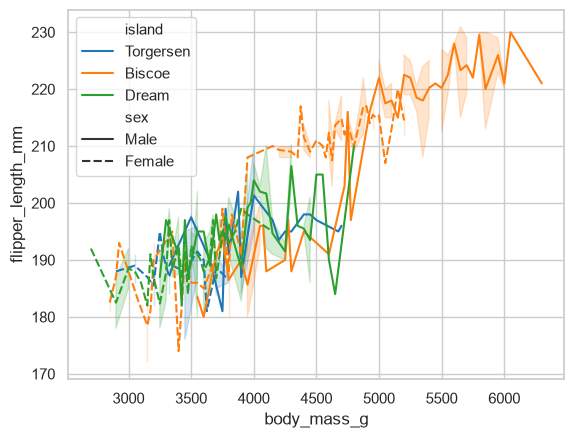

In [36]:
# Line plot: compare trends across islands and sex groups
sns.set_style('whitegrid')
sns.lineplot(data=penguins, x='body_mass_g', y='flipper_length_mm', hue='island', style='sex')
plt.show()

### **Join plots**
This joint plot combines a scatter view with distributions to show both the relationship and spread of the data.


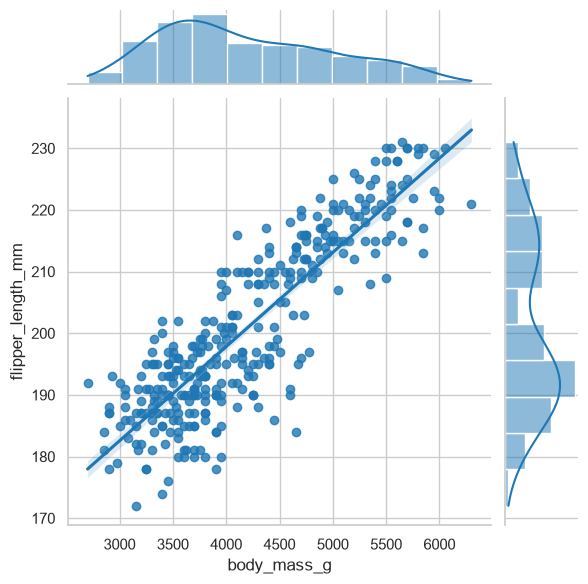

In [37]:
# Joint plot: show the relationship plus the distribution of both variables
sns.jointplot(data=penguins, x='body_mass_g', y='flipper_length_mm', kind='reg')
plt.show()

### **Bar Plot**
This bar plot compares total body mass by species and sex.


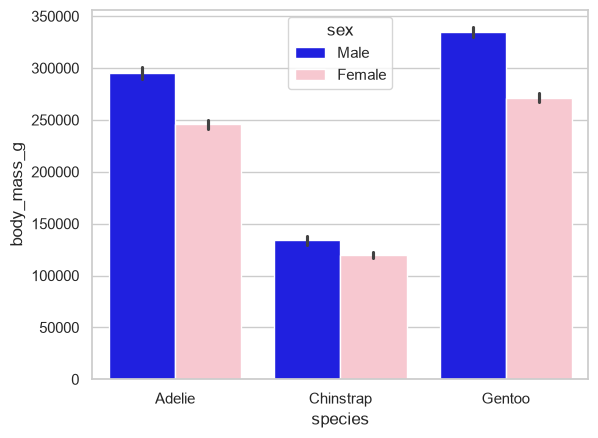

In [38]:
# Bar plot: total body mass by species and sex
# estimator: function to aggregate the data, default is mean
sns.barplot(data=penguins, x='species',
             y='body_mass_g', 
             hue='sex',
             palette={'Male':'blue', 'Female':'pink'},
             estimator=np.sum)
plt.show()

### **Count Plot**
This count plot shows how many penguins belong to each species and island.


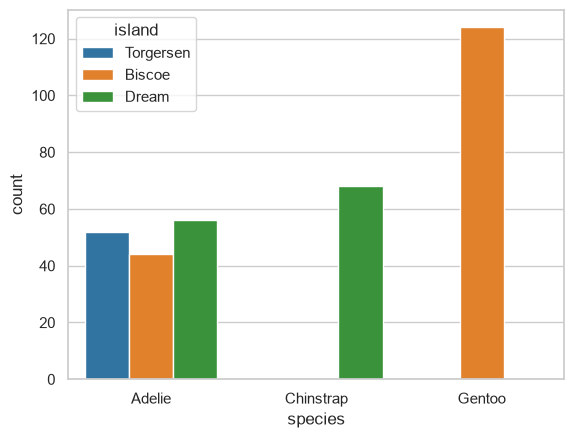

In [39]:
# Count plot: number of penguins per species and island
sns.countplot(data=penguins, x='species', hue='island')
plt.show()

### **Box Plot**
This box plot summarizes the median, spread, and outliers of body mass for each species.


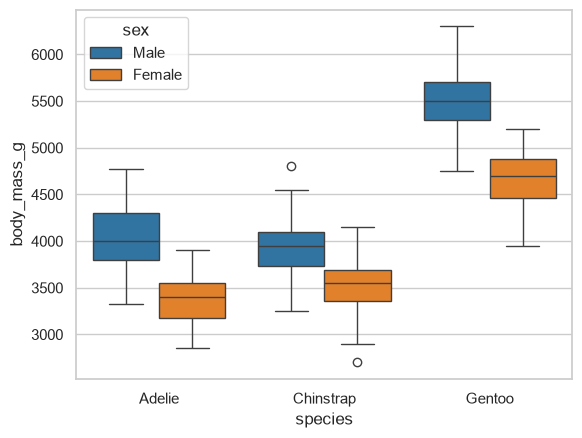

In [40]:
# Box plot: median, spread, and outliers for each species
sns.boxplot(data=penguins, x='species', y='body_mass_g', hue='sex')
plt.show()

### **Violin Plot**
This violin plot shows the full distribution shape, helping compare where values are most concentrated.


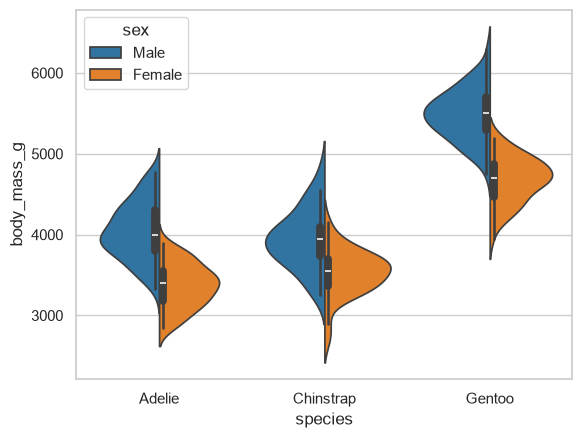

In [41]:
# Violin plot: distribution shape by species, split by sex
# kde : kernel density estimate, a way to visualize the distribution of data
# split : if True, separate the violins for each level of the hue variable
sns.violinplot(data=penguins, x='species', y='body_mass_g', hue='sex', split=True)
plt.show()

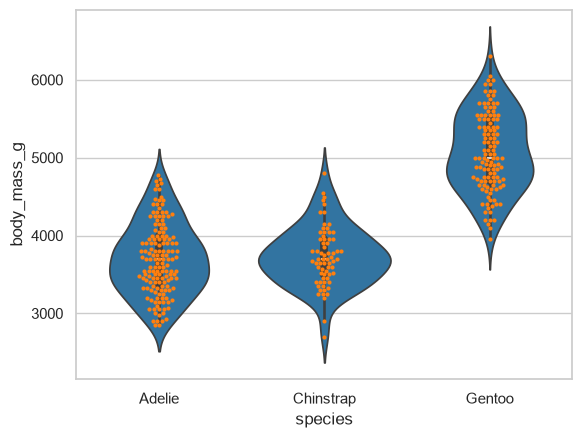

In [42]:
# Combine violin and swarm plots to see both distribution and individual points
# violinplot & swarmplot:
sns.violinplot(data=penguins, x='species', y='body_mass_g')
sns.swarmplot(data=penguins, x='species', y='body_mass_g',size=3)
plt.show()

### **kde Plot**
This KDE plot smooths the body mass distribution and compares species-level density curves.


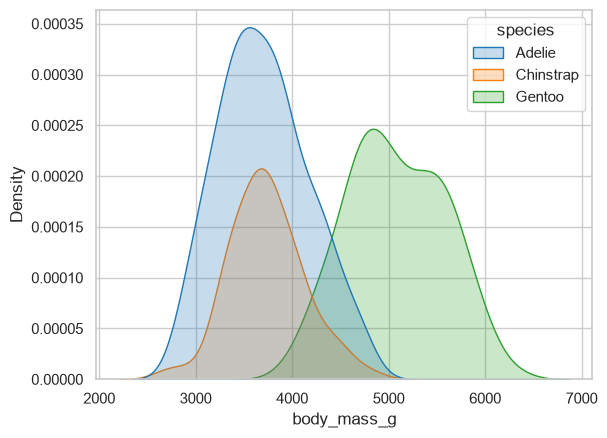

In [43]:
# KDE plot: smooth density curve for each species
sns.kdeplot(data=penguins, x='body_mass_g', hue='species', fill=True)
plt.show()

### **Heatmap**
This heatmap shows how strongly different penguin measurements are related to each other.


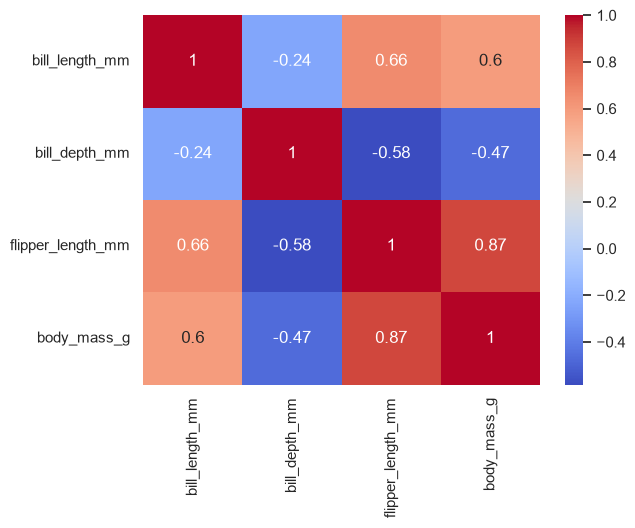

In [44]:
# Heatmap: correlation matrix for numeric features
columns = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
sns.heatmap(data=penguins[columns].corr(), annot=True, cmap='coolwarm')
plt.show()

### **Rug Plot**
This rug plot marks each body mass value along the axis to show where the data is concentrated.


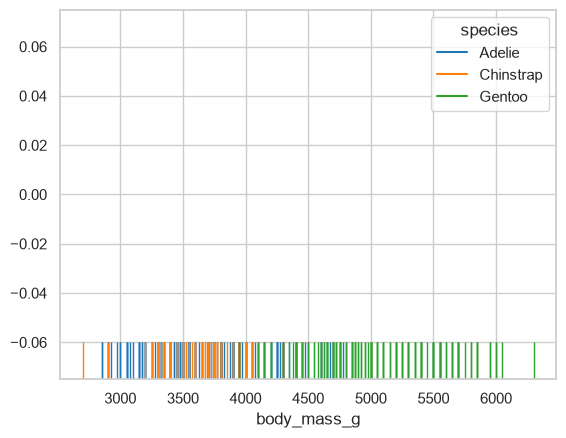

In [45]:
# Rug plot: show the density of values along the x-axis
sns.rugplot(data=penguins, x='body_mass_g', hue='species', height=0.1)
plt.show()

### **Pair plot**
This pair plot shows all pairwise relationships between the numeric variables, colored by species.


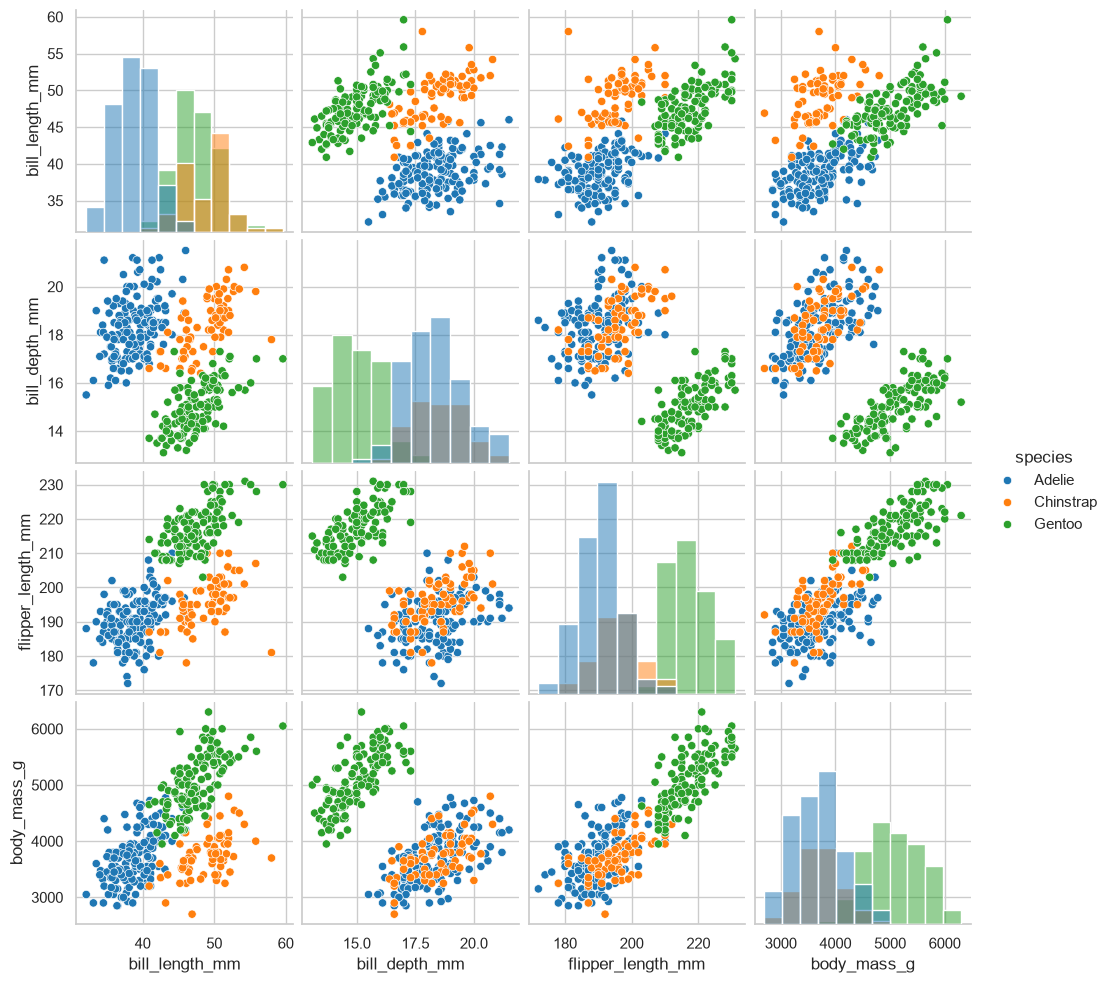

In [46]:
# Pair plot: compare several variables at once by species
sns.pairplot(data=penguins, hue='species',diag_kind='hist')
plt.show()

### **Pair grid**
This pair grid gives a flexible version of the pair plot with custom plots in each panel.


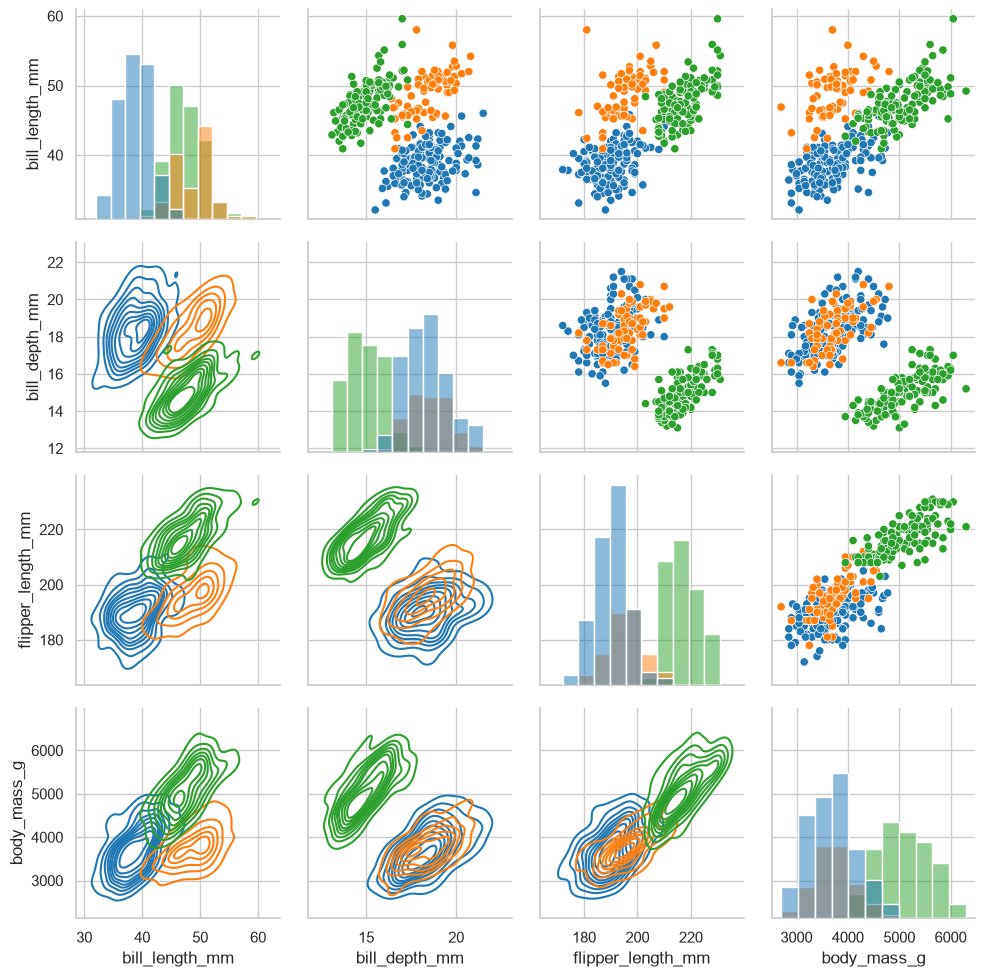

In [47]:
# PairGrid: custom matrix of scatter, KDE, and histogram panels
graph = sns.PairGrid(data=penguins, hue='species')
graph.map_upper(sns.scatterplot)
graph.map_lower(sns.kdeplot)
graph.map_diag(sns.histplot)
plt.show()